# Исследование факторов выживаемости и построение ML-классификатора

**Цель работы:** на основе датасета `game_of_thrones_train` предсказать, кто из персонажей книги умрет, а кто останется в живых. Выявить статистически значимые факторы и обучить на них ML-модель

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss, mean_squared_error
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

In [ ]:
df_train = pd.read_csv("game_of_thrones_train.csv")
df_test = pd.read_csv("game_of_thrones_test.csv")

In [ ]:
df_train.head(10)

,S.No,name,title,male,culture,dateOfBirth,mother,father,heir,house,...,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity,isAlive
0,1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,...,1.0,0.0,0.0,NaN,0,0,NaN,11,0.605351,0
1,2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,...,NaN,NaN,NaN,1.0,1,1,97.0,1,0.896321,1
2,3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.267559,1
3,4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,...,NaN,NaN,NaN,0.0,1,1,23.0,0,0.183946,0
4,5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,...,NaN,NaN,NaN,1.0,1,1,29.0,0,0.043478,1
5,6,Tommen Baratheon,NaN,1,NaN,NaN,Cersei Lannister,Robert Baratheon,Myrcella Baratheon,NaN,...,1.0,1.0,1.0,NaN,0,0,NaN,5,1.000000,1
6,7,Valarr Targaryen,Hand of the King,1,Valyrian,183.0,NaN,NaN,NaN,House Targaryen,...,NaN,NaN,NaN,1.0,1,1,26.0,0,0.431438,0
7,8,Viserys I Targaryen,NaN,1,NaN,NaN,Alyssa Targaryen,Baelon Targaryen,Rhaenyra Targaryen,NaN,...,1.0,1.0,1.0,NaN,0,0,NaN,5,0.678930,0
8,9,Wilbert,Ser,1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.006689,0
9,10,Wilbert Osgrey,Ser,1,NaN,NaN,NaN,NaN,NaN,House Osgrey,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.020067,1


Описание данных:

* **name**: Имя персонажа
* **Title**: Социальный статус или знатность
* **House**: Дом, к которому принадлежит персонаж
* **Culture**: Социальная группа, к которой принадлежит персонаж
* **book1/2/3/4/5**: Появление персонажа в книге
* **Is noble**: Знатность персонажа, основанное на титуле
* **Age**: Отсчет времени: 305 AC
* **male**: Мужчина или женщина
* **dateOfBirth**: дата рождения
* **Spouse**: Имя супруги/а персонажа
* **Father**: Имя отца персонажа
* **Mother**: Имя матери персонажа
* **Heir**: Имя наследника персонажа
* **Is married**: Состоит ли персонаж в браке
* **Is spouse alive**: Жив ли супруг/супруга
* **Is mother alive:** Жива ли мать персонажа
* **Is heir alive:** Жив ли наследник персонажа
* **Is father alive:** Указывает, жив ли отец персонажа
* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан
* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

---

## Часть 1. Предобработка данных

Многие признаки в датасете содержат пропуски (NaN). Заполнять пропуски категориальных (и булевых) данных средними значениями некорректно. Для их обработки мы применим метод **One-Hot Encoding (OHE)**

* **Категориальные признаки (Культура):** Сгруппированы похожие названия, затем применен OHE (созданы столбцы вида culture_Northmen из 0 и 1)
* **Булевы признаки с пропусками (Родственники):** Пропуск (NaN) — это тоже важная информация. С помощью OHE мы разбили каждый признак на 3 столбца. Например: isAliveHeir_Alive, isAliveHeir_Dead, isAliveHeir_Unknown
* **Возраст:** Аномальные (отрицательные) значения заменены на пропуски. Создан флаг-индикатор age_is_missing, а сами пропуски заполнены медианным значением

In [ ]:
def preprocess_data(df):
    data = df.copy()

    if 'name' in data.columns:
        data.drop(columns=['name', 'S.No', 'title', 'house', 'mother', 'father', 'heir', 'spouse'], inplace=True, errors='ignore')

    cult = {
        'Summer Islands': ['summer islands', 'summer islander', 'summer isles'],
        'Ghiscari':['ghiscari', 'ghiscaricari',  'ghis'],
        'Asshai':["asshai'i", 'asshai'],
        'Lysene': ['lysene', 'lyseni'],
        'Andal': ['andal', 'andals'],
        'Braavosi':['braavosi', 'braavos'],
        'Dornish': ['dornishmen', 'dorne', 'dornish'],
        'Myrish': ['myr', 'myrish', 'myrmen'],
        'Westermen': ['westermen', 'westerman', 'westerlands'],
        'Westerosi': ['westeros', 'westerosi'],
        'Stormlander': ['stormlands', 'stormlander'],
        'Norvoshi': ['norvos', 'norvoshi'],
        'Northmen':['the north', 'northmen'],
        'Free Folk': ['wildling', 'first men', 'free folk'],
        'Qartheen': ['qartheen', 'qarth'],
        'Reach':['the reach', 'reach', 'reachmen'],
    }

    def map_culture(c):
        if pd.isna(c): return 'Unknown'
        c = c.lower()
        for k, v in cult.items():
            if c in v: return k
        return 'Other'

    data['culture'] = data['culture'].apply(map_culture)
    data = pd.get_dummies(data, columns=['culture'], drop_first=True)

    rel_cols =['isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse']
    for col in rel_cols:
        data[col] = data[col].astype(float)

        dummies = pd.get_dummies(data[col], prefix=col, dummy_na=True)

        rename_dict = {
            f"{col}_0.0": f"{col}_Dead",
            f"{col}_1.0": f"{col}_Alive",
            f"{col}_nan": f"{col}_Unknown"
        }
        dummies.rename(columns=rename_dict, inplace=True)

        data = pd.concat([data, dummies], axis=1)
        data.drop(columns=[col], inplace=True)

    data['age_is_missing'] = data['age'].isna().astype(int)
    data.loc[data['age'] < 0, 'age'] = np.nan
    data['age'] = data['age'].fillna(data['age'].median())

    if 'dateOfBirth' in data.columns:
        data['dateOfBirth'] = data['dateOfBirth'].fillna(data['dateOfBirth'].median())

    for col in data.columns:
        if data[col].dtype == 'bool':
            data[col] = data[col].astype(int)

    return data

df_train_clean = preprocess_data(df_train)
df_test_clean = preprocess_data(df_test)

df_train_clean, df_test_clean = df_train_clean.align(df_test_clean, join='left', axis=1, fill_value=0)

if 'isAlive' in df_test_clean.columns:
    df_test_clean.drop(columns=['isAlive'], inplace=True)

print(f"Размер обучающей выборки до очистки/после очистки: {df_train.shape} / {df_train_clean.shape}")
print(f"Размер тестовой выборки до очистки/после очистки: {df_test.shape} / {df_test_clean.shape}")

df_train_clean.head(3)

Размер обучающей выборки до очистки/после очистки: (1557, 26) / (1557, 42)
Размер тестовой выборки до очистки/после очистки: (389, 25) / (389, 41)


,male,dateOfBirth,book1,book2,book3,book4,book5,isMarried,isNoble,age,...,isAliveFather_Dead,isAliveFather_Alive,isAliveFather_Unknown,isAliveHeir_Dead,isAliveHeir_Alive,isAliveHeir_Unknown,isAliveSpouse_Dead,isAliveSpouse_Alive,isAliveSpouse_Unknown,age_is_missing
0,1,272.0,0,0,0,0,0,0,0,24.0,...,1,0,0,1,0,0,0,0,1,1
1,1,208.0,1,1,1,1,1,1,1,97.0,...,0,0,1,0,0,1,0,1,0,0
2,1,272.0,0,0,0,1,0,0,1,24.0,...,0,0,1,0,0,1,0,0,1,1


##### Что мы убрали (удаленные столбцы):
* **S.No, name** — порядковый номер и имя (это не числовые признаки)
* **title, house** — титул и дом (очень много уникальных текстовых значений и пропусков, сложно перевести в числа без потери качества на данном этапе)
* **mother, father, heir, spouse** — имена родственников (текстовые данные, которые алгоритм не сможет обработать)
* Исходные столбцы **culture, isAliveMother, isAliveFather, isAliveHeir, isAliveSpouse** — они были удалены, так как вместо них мы создали новые
---

## Часть 2. Разведочный анализ (Анализ корреляций)

Перед проведением строгих статистических тестов, построим матрицы корреляций.

Это поможет визуально определить факторы, сильнее всего связанные с целевой переменной, а также выявить проблему мультиколлинеарности


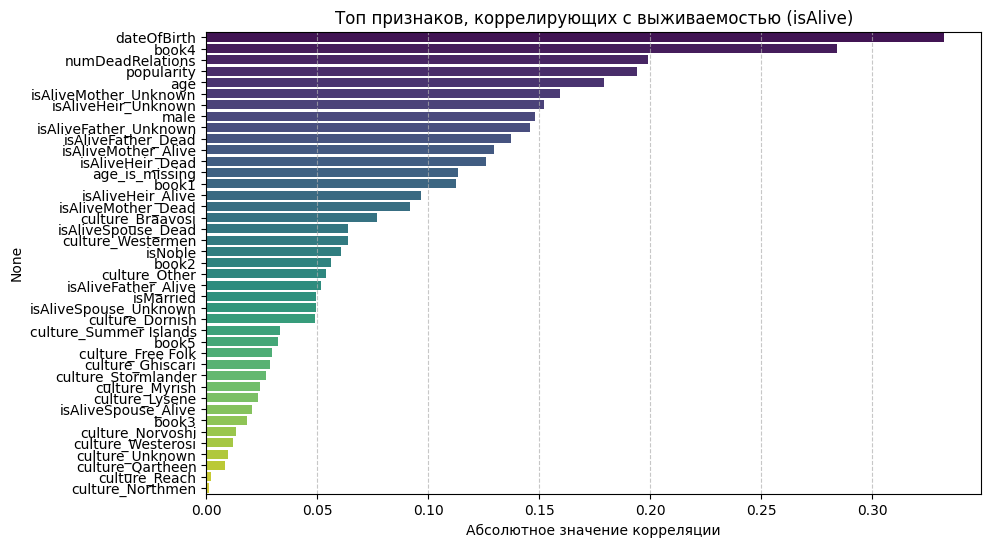

In [ ]:
# Топ признаков, влияющих на выживаемость
full_corr = df_train_clean.corr()
top_target_corr = full_corr['isAlive'].drop('isAlive').abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_target_corr.values, y=top_target_corr.index, palette='viridis')
plt.title("Топ признаков, коррелирующих с выживаемостью (isAlive)")
plt.xlabel("Абсолютное значение корреляции")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

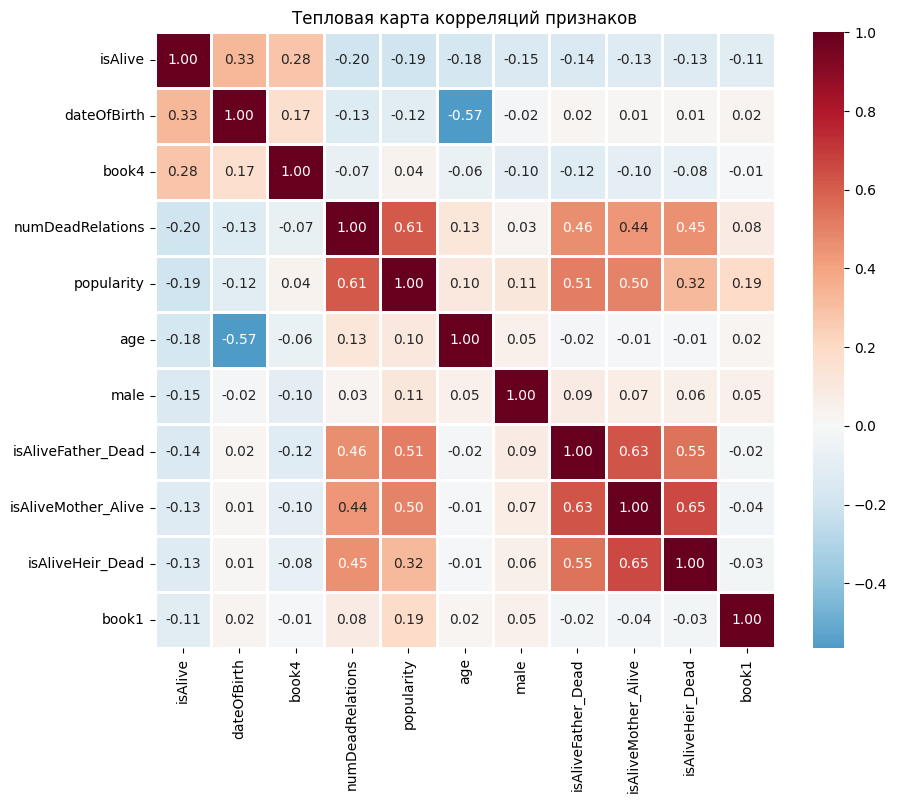

In [ ]:
# Тепловая корреляции признаков друг с другом
exclude_cols = [
    'culture_Other', 'isAliveFather_Alive', 'isMarried', 'isAliveSpouse_Unknown',
    'culture_Dornish', 'culture_Summer Islands', 'book5', 'culture_Free Folk',
    'culture_Ghiscari', 'culture_Stormlander', 'culture_Myrish', 'culture_Lysene',
    'isAliveSpouse_Alive', 'book3', 'culture_Norvoshi', 'culture_Westerosi',
    'culture_Unknown', 'culture_Qartheen', 'culture_Reach', 'culture_Northmen',
    'isAliveMother_Unknown', 'isAliveHeir_Unknown', 'age_is_missing', 'isAliveFather_Unknown'
]

available_cols = [col for col in df_train_clean.columns if col not in exclude_cols]
corr_matrix = df_train_clean[available_cols].corr()

top_with_target = corr_matrix['isAlive'].abs().sort_values(ascending=False).head(11).index.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(df_train_clean[top_with_target].corr(), annot=True, cmap='RdBu_r', center=0, fmt=".2f", linewidths=1)
plt.title("Тепловая карта корреляций признаков")
plt.show()

In [ ]:
# Поиск мультиколлинеарности
inter_corr = corr_matrix.stack().reset_index()
inter_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']

high_inter_corr = inter_corr[
    (inter_corr['Feature 1'] != inter_corr['Feature 2']) &
    (inter_corr['Correlation'].abs() > 0.45) &
    (inter_corr['Feature 1'] != 'isAlive') &
    (inter_corr['Feature 2'] != 'isAlive')
].sort_values(by='Correlation', ascending=False)

high_inter_corr.iloc[::2].reset_index(drop=True)

,Feature 1,Feature 2,Correlation
0,isAliveHeir_Alive,isAliveMother_Dead,0.652963
1,isAliveMother_Alive,isAliveHeir_Dead,0.652751
2,isAliveFather_Dead,isAliveMother_Alive,0.626791
3,popularity,numDeadRelations,0.613759
4,isAliveMother_Dead,isAliveFather_Dead,0.591978
5,isAliveFather_Dead,isAliveHeir_Dead,0.547233
6,isAliveFather_Dead,isAliveHeir_Alive,0.513770
7,popularity,isAliveFather_Dead,0.512052
8,isAliveMother_Alive,popularity,0.495818
9,popularity,isAliveHeir_Alive,0.471462


### Вывод по корреляционному анализу

**Связь с таргетом**:

 Визуальный анализ показал, что наиболее сильное линейное влияние на выживаемость оказывают дата рождения, участие в 4-й книге, пол, популярность и возраст

**Мультиколлинеарность**:

Были выявлены пары с заметной корреляцией. Однако ни одна из выявленных связей не превышает критический порог (0.8 - 0.9). Мы принимаем решение не удалять эти признаки вручную, так как встроенная в Логистическую регрессию [L2-регуляризация](https://python-school.ru/blog/osnovy-ml/regularization-l1-l2/) способна самостоятельно сгладить этот эффект без потери полезной информации

---

## Часть 3. Проверка статистических гипотез

Реализованы собственные функции для проверки гипотез:
- **Критерий независимости Хи-квадрат** (для категориальных/бинарных данных)
- **Критерий корреляции Пирсона** (для количественных данных)

Уровень значимости 0.05. Если вычисленный p-value меньше 0.05, то нулевая гипотеза $H_0$ (об отсутствии связи) отвергается. Фактор признается статистически значимым

In [ ]:
def manual_chi2_test(x, y, alpha=0.05, feature_name=""):
    x_levels, y_levels = np.unique(x), np.unique(y)
    observed = np.zeros((len(x_levels), len(y_levels)))
    for i, x_val in enumerate(x_levels):
        for j, y_val in enumerate(y_levels):
            observed[i, j] = np.sum((x == x_val) & (y == y_val))

    row_totals = observed.sum(axis=1)
    col_totals = observed.sum(axis=0)
    total = observed.sum()

    expected = np.outer(row_totals, col_totals) / total
    expected[expected == 0] = 1e-10

    chi2_stat = np.sum((observed - expected)**2 / expected)
    df = (len(x_levels) - 1) * (len(y_levels) - 1)

    if df <= 0: return False

    p_value = stats.chi2.sf(chi2_stat, df)
    crit_val = stats.chi2.ppf(1 - alpha, df)

    print(f"\n[Хи-квадрат] {feature_name} vs isAlive")
    print(f"Статистика: {chi2_stat:.4f} | p-value: {p_value:.4e}")
    print(f"Критическая область: [{crit_val:.4f}, +inf)")

    is_significant = p_value < alpha
    print("Вердикт:", "ОТВЕРГАЕМ H0 (Фактор значим)" if is_significant else "ПРИНИМАЕМ H0 (Связи нет)")
    return is_significant

def manual_pearson_test(x, y, alpha=0.05, feature_name=""):
    n = len(x)
    mean_x, mean_y = np.mean(x), np.mean(y)

    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x)**2) * np.sum((y - mean_y)**2))
    r = numerator / denominator if denominator != 0 else 0

    df = n - 2
    if df <= 0: return False

    if abs(r) == 1.0:
        t_stat = np.inf
        p_value = 0.0
    else:
        t_stat = r * np.sqrt(df) / np.sqrt(1 - r**2)
        p_value = 2 * stats.t.sf(np.abs(t_stat), df)

    t_crit = stats.t.ppf(1 - alpha/2, df)

    print(f"\n[Пирсон] {feature_name} vs isAlive")
    print(f"r: {r:.4f} | t-стат: {t_stat:.4f} | p-value: {p_value:.4e}")
    print(f"Критическая область: (-inf, {-t_crit:.4f}] U [{t_crit:.4f}, +inf)")

    is_significant = p_value < alpha
    print("Вердикт:", "ОТВЕРГАЕМ H0 (Фактор значим)" if is_significant else "ПРИНИМАЕМ H0 (Связи нет)")
    return is_significant

target = df_train_clean['isAlive']
significant_features = []

features_to_test = [col for col in df_train_clean.columns if col != 'isAlive']

print(f"СТАТИСТИЧЕСКАЯ ПРОВЕРКИ ВСЕХ {len(features_to_test)} ПРИЗНАКОВ")

for feature in features_to_test:
    if df_train_clean[feature].nunique() < 2:
        continue
    if df_train_clean[feature].nunique() == 2:
        is_sig = manual_chi2_test(df_train_clean[feature], target, feature_name=feature)
    else:
        is_sig = manual_pearson_test(df_train_clean[feature], target, feature_name=feature)

    if is_sig:
        significant_features.append(feature)

print(f"\nИТОГ: Статистический фильтр пропустил {len(significant_features)} признаков из {len(features_to_test)}.")
print(f"Список для ML-модели:\n{significant_features}")

СТАТИСТИЧЕСКАЯ ПРОВЕРКИ ВСЕХ 41 ПРИЗНАКОВ

[Хи-квадрат] male vs isAlive
Статистика: 34.2385 | p-value: 4.8755e-09
Критическая область: [3.8415, +inf)
Вердикт: ОТВЕРГАЕМ H0 (Фактор значим)

[Пирсон] dateOfBirth vs isAlive
r: 0.3325 | t-стат: 13.9037 | p-value: 1.6446e-41
Критическая область: (-inf, -1.9615] U [1.9615, +inf)
Вердикт: ОТВЕРГАЕМ H0 (Фактор значим)

[Хи-квадрат] book1 vs isAlive
Статистика: 19.6946 | p-value: 9.0856e-06
Критическая область: [3.8415, +inf)
Вердикт: ОТВЕРГАЕМ H0 (Фактор значим)

[Хи-квадрат] book2 vs isAlive
Статистика: 4.8824 | p-value: 2.7133e-02
Критическая область: [3.8415, +inf)
Вердикт: ОТВЕРГАЕМ H0 (Фактор значим)

[Хи-квадрат] book3 vs isAlive
Статистика: 0.5287 | p-value: 4.6716e-01
Критическая область: [3.8415, +inf)
Вердикт: ПРИНИМАЕМ H0 (Связи нет)

[Хи-квадрат] book4 vs isAlive
Статистика: 125.5938 | p-value: 3.7732e-29
Критическая область: [3.8415, +inf)
Вердикт: ОТВЕРГАЕМ H0 (Фактор значим)

[Хи-квадрат] book5 vs isAlive
Статистика: 1.6477 | p-

In [ ]:
# Дополнительные ранговвые тесты
print("\n   Критерий Спирмена")
print("Проверяем: Popularity vs isAlive")
rho, p_val_spearman = stats.spearmanr(df_train_clean['popularity'], df_train_clean['isAlive'])

print(f"Коэффициент Спирмена: {rho:.4f}")
print(f"p-value: {p_val_spearman:.4e}")
if p_val_spearman < 0.05:
    print("Вердикт: Связь статистически ЗНАЧИМА")
    if 'popularity' not in significant_features:
        significant_features.append('popularity')
else:
    print("Вердикт: Связь незначима.")


print("\n   Критерий Кендалла")
print("Проверяем: numDeadRelations vs isAlive")
tau, p_val_kendall = stats.kendalltau(df_train_clean['numDeadRelations'], df_train_clean['isAlive'])

print(f"Коэффициент Кендалла: {tau:.4f}")
print(f"p-value: {p_val_kendall:.4e}")
if p_val_kendall < 0.05:
    print("Вердикт: Связь статистически ЗНАЧИМА")
    if 'numDeadRelations' not in significant_features:
        significant_features.append('numDeadRelations')
else:
    print("Вердикт: Связь незначима.")


   Критерий Спирмена
Проверяем: Popularity vs isAlive
Коэффициент Спирмена: -0.2315
p-value: 2.1636e-20
Вердикт: Связь статистически ЗНАЧИМА

   Критерий Кендалла
Проверяем: numDeadRelations vs isAlive
Коэффициент Кендалла: -0.1789
p-value: 1.0798e-12
Вердикт: Связь статистически ЗНАЧИМА


### Вывод по статистическому анализу

Сплошное тестирование позволило отсеять информационный «шум» (например, принадлежность к большинству культур не имеет математически доказанной связи с выживаемостью). Из 41 признаков гипотезу $H_0$ (о независимости от таргета) смогли отклонить только 23 признака. Дополнительная проверка ключевых количественных параметров ранговыми критериями (Спирмена и Кендалла) полностью подтвердила результаты линейных тестов

---

## Часть 4. Обучение ML-моделей

Мы обучаем две базовые модели исключительно на 23 отобранных статистически значимых факторах. Выборка разделена на обучающую (80%) и валидационную (20%)

- **Логистическая регрессия**: Идеально подходит для классификации. В качестве функции потерь используется Log Loss

- **Линейная регрессия**: Применена как линейная модель вероятности. Использует порог классификации 0.5 и функцию потерь MSE

In [ ]:
X = df_train_clean[significant_features]
y = df_train_clean['isAlive']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Логистическая Регрессия
model_log = LogisticRegression(random_state=42, max_iter=1000)
model_log.fit(X_train, y_train)

y_prob_train = model_log.predict_proba(X_train)
y_prob_test = model_log.predict_proba(X_test)
y_pred_log = model_log.predict(X_test)

log_loss_train = log_loss(y_train, y_prob_train)
log_loss_test = log_loss(y_test, y_prob_test)
acc_log = accuracy_score(y_test, y_pred_log)
f1_log = f1_score(y_test, y_pred_log)

print("Результаты: Логистическая Регрессия")
print(f"Log Loss (Train): {log_loss_train:.4f}")
print(f"Log Loss (Test):  {log_loss_test:.4f}")
print(f"Accuracy (Test):  {acc_log:.4f}")
print(f"F1-Score (Test):  {f1_log:.4f}\n")


# 2. Линейная Регрессия
model_lin = LinearRegression()
model_lin.fit(X_train, y_train)

y_pred_lin_train = model_lin.predict(X_train)
y_pred_lin_test = model_lin.predict(X_test)

y_class_lin_test = [1 if x >= 0.5 else 0 for x in y_pred_lin_test]

mse_train = mean_squared_error(y_train, y_pred_lin_train)
mse_test = mean_squared_error(y_test, y_pred_lin_test)
acc_lin = accuracy_score(y_test, y_class_lin_test)
f1_lin = f1_score(y_test, y_class_lin_test)

print("Результаты: Линейная Регрессия")
print(f"MSE (Train):     {mse_train:.4f}")
print(f"MSE (Test):      {mse_test:.4f}")
print(f"Accuracy (Test): {acc_lin:.4f}")
print(f"F1-Score (Test): {f1_lin:.4f}")

Результаты: Логистическая Регрессия
Log Loss (Train): 0.3643
Log Loss (Test):  0.4326
Accuracy (Test):  0.8237
F1-Score (Test):  0.8944

Результаты: Линейная Регрессия
MSE (Train):     0.1292
MSE (Test):      0.1514
Accuracy (Test): 0.7981
F1-Score (Test): 0.8805


### Вывод по обучению моделей

Логистическая регрессия продемонстрировала лучшие результаты по всем ключевым метрикам. Особое внимание стоит уделить F1-Score (0.8944). Высокое значение этой метрики (выше, чем Accuracy) подтверждает, что модель обладает хорошим балансом между точностью и полнотой предсказаний

Это означает, что алгоритм одинаково эффективно идентифицирует как выживших, так и погибших персонажей, не допуская критического перекоса в сторону большинства классов. Отсутствие переобучения подтверждается близкими значениями Log Loss на обеих выборках

---

## Часть 5. Итоговое прогнозирование и диагностика модели

Применяем лучшую обученную модель (Logistic Regression) к тестовому датасету `game_of_thrones_test.csv`

In [ ]:
X_blind_test = df_test_clean[significant_features]

final_predictions = model_log.predict(X_blind_test)
final_probabilities = model_log.predict_proba(X_blind_test)[:, 1]

df_test['Predicted_IsAlive'] = final_predictions
df_test['Survival_Probability'] = final_probabilities

train_survival_rate = df_train_clean['isAlive'].mean()
predicted_survival_rate = final_predictions.mean()

print(f"Доля выживших в обучающей выборке: {train_survival_rate:.1%}")
print(f"Доля выживших в прогнозе модели: {predicted_survival_rate:.1%}\n")

print("Топ-5 персонажей, которые скорее всего выживут:")
display(df_test.sort_values(by='Survival_Probability', ascending=False).head(5)[['name', 'house', 'Survival_Probability']])

print("\nТоп-5 персонажей, которые скорее всего умрут:")
display(df_test.sort_values(by='Survival_Probability', ascending=True).head(5)[['name', 'house', 'Survival_Probability']])

Доля выживших в обучающей выборке: 77.8%
Доля выживших в прогнозе модели: 84.1%

Топ-5 персонажей, которые скорее всего выживут:


,name,house,Survival_Probability
127,Doreah,House Targaryen,1.000000
311,Rhaego,House Targaryen,1.000000
96,Bellegere Otherys,NaN,0.991224
8,Monster,NaN,0.990553
89,Balon Greyjoy,NaN,0.988638



Топ-5 персонажей, которые скорее всего умрут:


,name,house,Survival_Probability
270,Visenya Targaryen,House Targaryen,1.731409e-44
383,Laena Velaryon,House Velaryon,9.126785e-31
119,Daemon Targaryen,House Targaryen,5.786651e-30
62,Addam Velaryon,House Velaryon,1.667525e-29
116,Corlys Velaryon,House Velaryon,1.676763e-29


### Итоговый вывод

В ходе лабораторной работы была успешно решена задача бинарной классификации. Мы провели комплексную предобработку, математически доказали значимость 23 факторов и обучили модель с точностью **>82%**

Проверка на адекватность показала, что предсказанное распределение выживаемости (84.1%) близко к исходному (77.8%), что подтверждает стабильную и логичную работу алгоритма на абсолютно новых данных.